In [1]:
# Import pandas for data manipulation and analysis
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Import StandardScaler for scaling the production values
from sklearn.preprocessing import StandardScaler

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

# ---------------------------------------------------------
# TensorFlow is used to build and train the deep learning
# models.
#
# Sequential is used to create models layer by layer.
#
# SimpleRNN is the basic recurrent neural network layer.
#
# LSTM is used to build the Long Short Term Memory model.
#
# GRU is used to build the Gated Recurrent Unit model.
#
# Dense is used for the final prediction layer.
#
# Adam is the optimizer used to update model weights.
#
# EarlyStopping helps prevent unnecessary training when
# validation loss stops improving.
# ---------------------------------------------------------

# Exploratory Data Analysis

In [2]:
# Load the monthly milk production dataset
df = pd.read_csv('monthly_milk_production.csv')

# Display the first five rows
print("First five rows of the dataset:")
df.head()




First five rows of the dataset:


,Date,Production
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


In [3]:
# Display the number of rows and columns
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(168, 2)


In [4]:
# Display information about the dataset
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Date        168 non-null    object
 1   Production  168 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.8+ KB
None


In [5]:
# Convert the Date column from text format to datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Display the data types after conversion
print(df.dtypes)

# Display the first five rows
print(df.head())

Date          datetime64[ns]
Production             int64
dtype: object
        Date  Production
0 1962-01-01         589
1 1962-02-01         561
2 1962-03-01         640
3 1962-04-01         656
4 1962-05-01         727


In [6]:
# Check the number of missing values in every column
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
Date          0
Production    0
dtype: int64


In [7]:
# Check the total number of duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [8]:
# Display descriptive statistics for the Production column
print("Descriptive Statistics:")
print(df['Production'].describe())

Descriptive Statistics:
count    168.000000
mean     754.708333
std      102.204524
min      553.000000
25%      677.750000
50%      761.000000
75%      824.500000
max      969.000000
Name: Production, dtype: float64


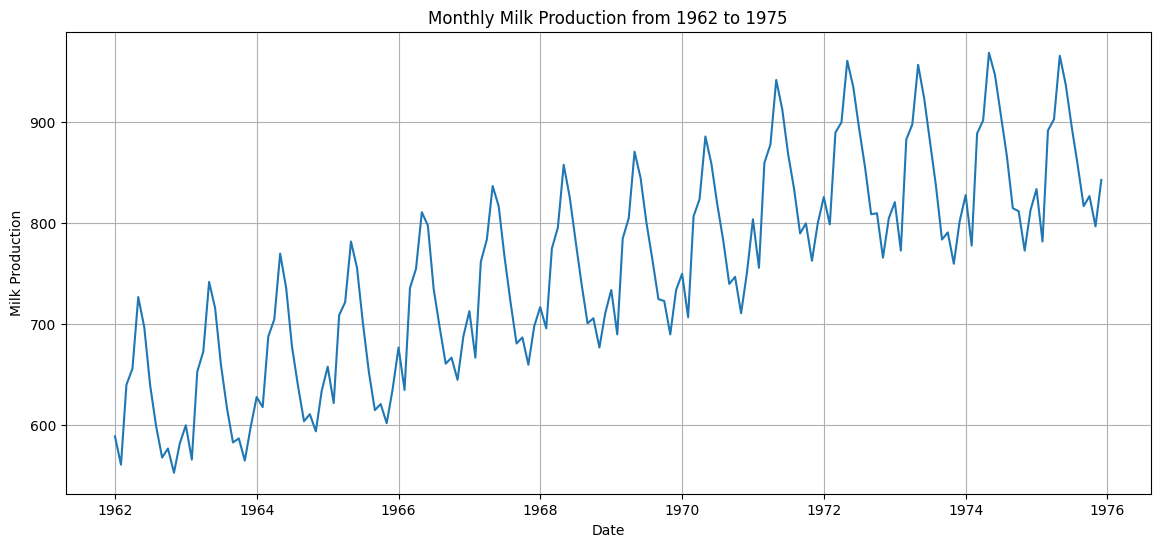

In [9]:
# Create a figure for the time series
plt.figure(figsize=(14, 6))

# Plot Date against Production
plt.plot(
    df['Date'],
    df['Production']
)

# Add title
plt.title('Monthly Milk Production from 1962 to 1975')

# Add x axis label
plt.xlabel('Date')

# Add y axis label
plt.ylabel('Milk Production')

# Add grid for easier interpretation
plt.grid(True)

# Display the plot
plt.show()

In [10]:
# Extract the year from the Date column
df['Year'] = df['Date'].dt.year

# Extract the month number from the Date column
df['Month'] = df['Date'].dt.month

# Display the updated dataset
print(df.head())

        Date  Production  Year  Month
0 1962-01-01         589  1962      1
1 1962-02-01         561  1962      2
2 1962-03-01         640  1962      3
3 1962-04-01         656  1962      4
4 1962-05-01         727  1962      5


In [11]:
# Calculate average monthly production for each year
yearly_production = df.groupby('Year')['Production'].mean()

# Display yearly average production
print("Average Production by Year:")
print(yearly_production)

Average Production by Year:
Year
1962    615.750000
1963    630.000000
1964    658.750000
1965    673.083333
1966    708.750000
1967    732.916667
1968    748.833333
1969    763.916667
1970    782.000000
1971    834.083333
1972    854.166667
1973    842.583333
1974    858.416667
1975    862.666667
Name: Production, dtype: float64


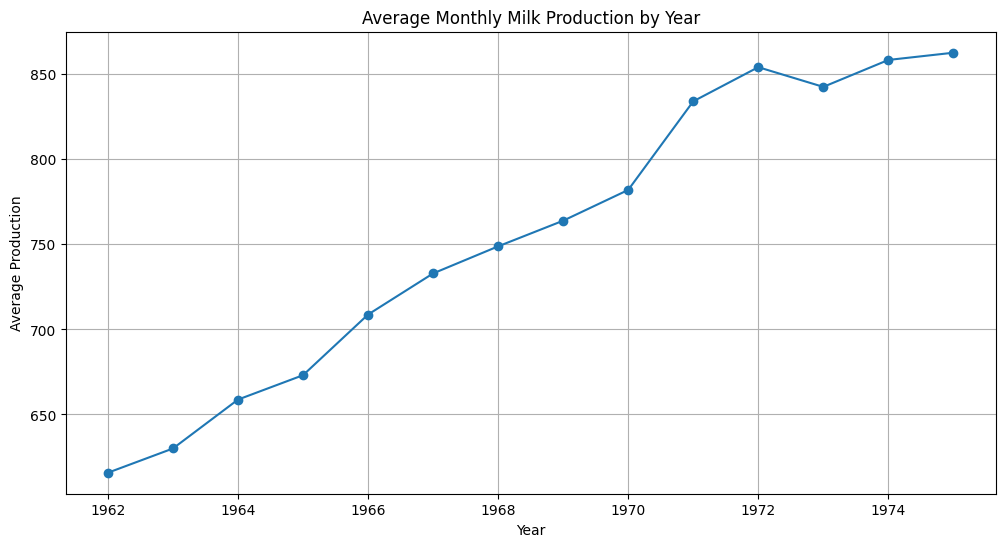

In [12]:
# Create a figure
plt.figure(figsize=(12, 6))

# Plot yearly average production
plt.plot(
    yearly_production.index,
    yearly_production.values,
    marker='o'
)

# Add title
plt.title('Average Monthly Milk Production by Year')

# Add labels
plt.xlabel('Year')
plt.ylabel('Average Production')

# Add grid
plt.grid(True)

# Display plot
plt.show()

In [13]:
# Calculate the average production for each month
monthly_average = df.groupby('Month')['Production'].mean()

# Display monthly averages
print("Average Production by Month:")
print(monthly_average)

Average Production by Month:
Month
1     727.071429
2     689.285714
3     783.500000
4     800.071429
5     862.785714
6     836.142857
7     788.071429
8     747.500000
9     706.642857
10    711.857143
11    682.571429
12    721.000000
Name: Production, dtype: float64


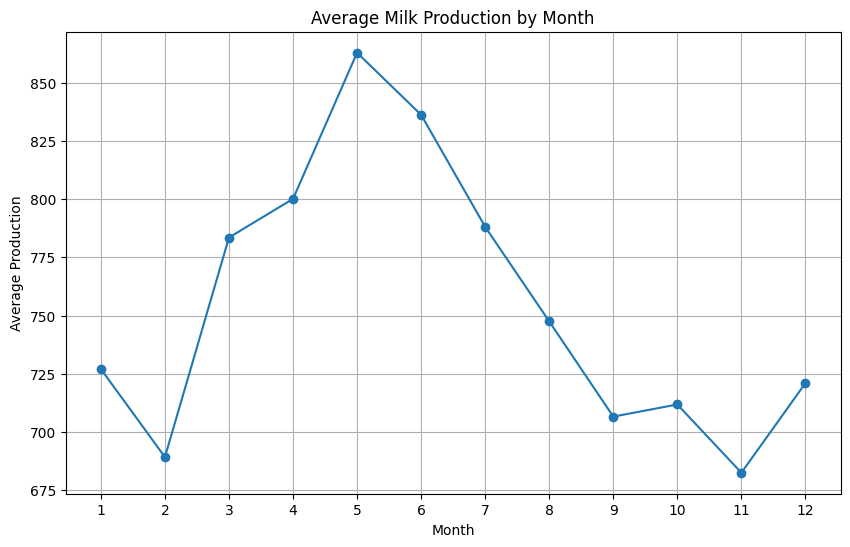

In [14]:
# Create a figure
plt.figure(figsize=(10, 6))

# Plot average production for each month
plt.plot(
    monthly_average.index,
    monthly_average.values,
    marker='o'
)

# Add title
plt.title('Average Milk Production by Month')

# Add labels
plt.xlabel('Month')
plt.ylabel('Average Production')

# Set month numbers from 1 to 12
plt.xticks(range(1, 13))

# Add grid
plt.grid(True)

# Display the plot
plt.show()

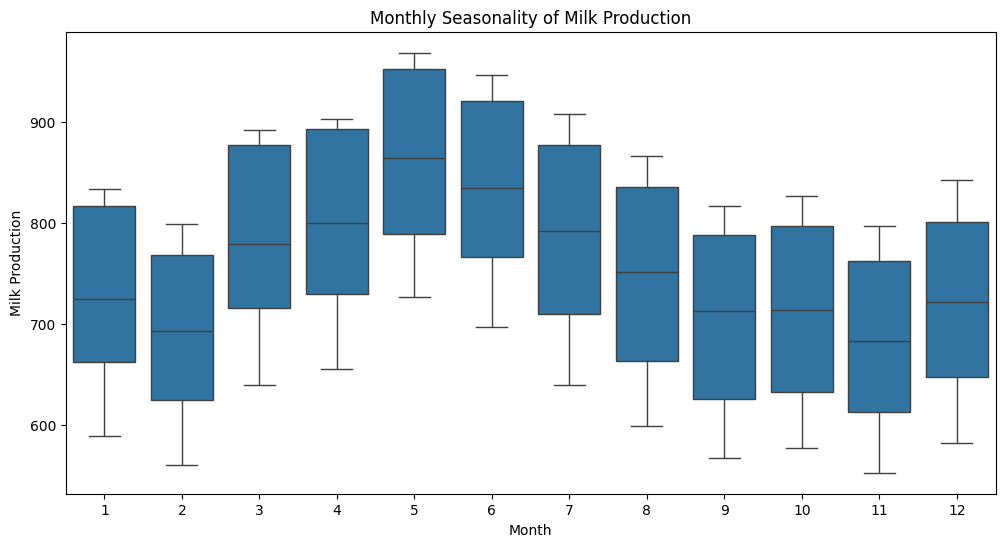

In [15]:
# Create a figure
plt.figure(figsize=(12, 6))

# Create box plots for production values grouped by month
sns.boxplot(
    data=df,
    x='Month',
    y='Production'
)

# Add title
plt.title('Monthly Seasonality of Milk Production')

# Add labels
plt.xlabel('Month')
plt.ylabel('Milk Production')

# Display the plot
plt.show()

In [16]:
# Calculate the first quartile
Q1 = df['Production'].quantile(0.25)

# Calculate the third quartile
Q3 = df['Production'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower boundary for detecting outliers
lower_bound = Q1 - 1.5 * IQR

# Calculate the upper boundary for detecting outliers
upper_bound = Q3 + 1.5 * IQR

# Display the calculated boundaries
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 677.75
Q3: 824.5
IQR: 146.75
Lower Bound: 457.625
Upper Bound: 1044.625


In [17]:
# Select observations that fall outside the IQR boundaries
outliers = df[
    (df['Production'] < lower_bound) |
    (df['Production'] > upper_bound)
]

# Display the detected outliers
print("Detected Outliers:")
print(outliers)

# Display the number of outliers
print("\nNumber of Outliers:", len(outliers))

Detected Outliers:
Empty DataFrame
Columns: [Date, Production, Year, Month]
Index: []

Number of Outliers: 0


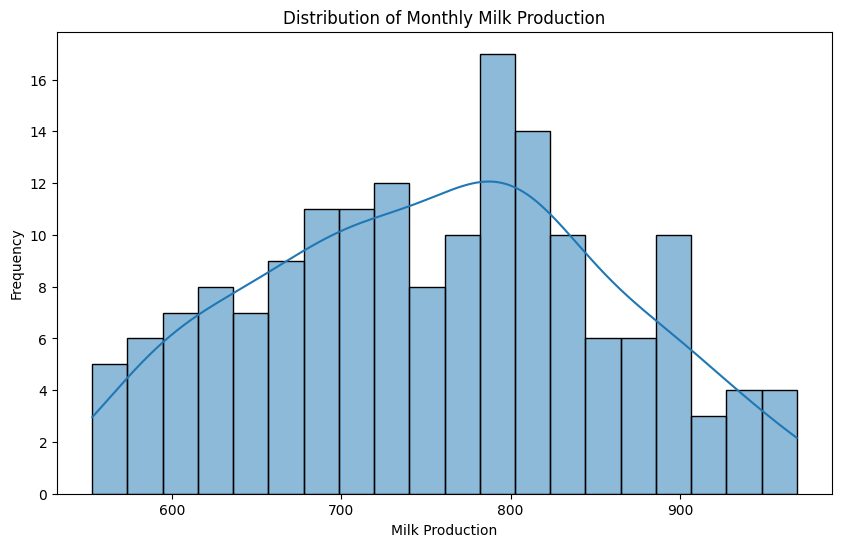

In [18]:
# Create a histogram of production values
plt.figure(figsize=(10, 6))

# Plot the distribution
sns.histplot(
    df['Production'],
    bins=20,
    kde=True
)

# Add title
plt.title('Distribution of Monthly Milk Production')

# Add labels
plt.xlabel('Milk Production')
plt.ylabel('Frequency')

# Display the plot
plt.show()

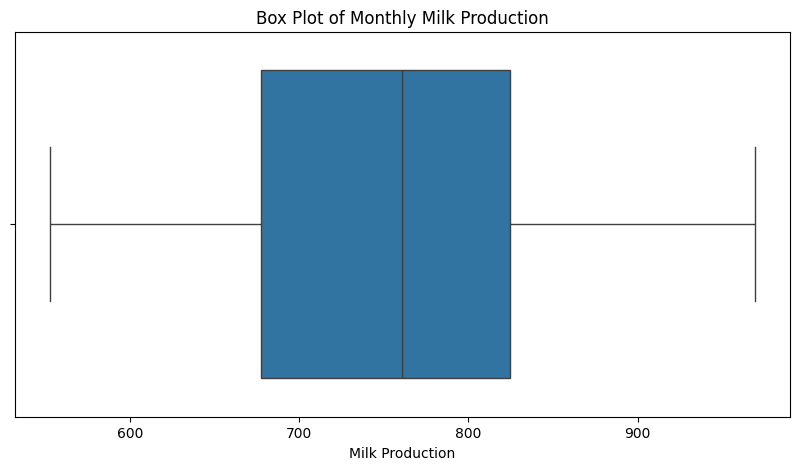

In [19]:
# Create a figure
plt.figure(figsize=(10, 5))

# Create a box plot for Production
sns.boxplot(
    x=df['Production']
)

# Add title
plt.title('Box Plot of Monthly Milk Production')

# Add x axis label
plt.xlabel('Milk Production')

# Display the plot
plt.show()

In [20]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler using the Production column
# The double brackets keep the result as a DataFrame with one column
production_scaled = scaler.fit_transform(
    df[['Production']]
)

# Display the first five scaled values
print("First five scaled production values:")
print(production_scaled[:5])

First five scaled production values:
[[-1.62618756]
 [-1.90096705]
 [-1.12569634]
 [-0.96867949]
 [-0.27191721]]


In [21]:
# Add the scaled production values to the dataset
df['Production_Scaled'] = production_scaled

# Display the original and scaled values
print(
    df[
        ['Date', 'Production', 'Production_Scaled']
    ].head(10)
)

        Date  Production  Production_Scaled
0 1962-01-01         589          -1.626188
1 1962-02-01         561          -1.900967
2 1962-03-01         640          -1.125696
3 1962-04-01         656          -0.968679
4 1962-05-01         727          -0.271917
5 1962-06-01         697          -0.566324
6 1962-07-01         640          -1.125696
7 1962-08-01         599          -1.528052
8 1962-09-01         568          -1.832272
9 1962-10-01         577          -1.743950


In [22]:
# Calculate the mean of the scaled production values
scaled_mean = df['Production_Scaled'].mean()

# Calculate the standard deviation of the scaled production values
scaled_std = df['Production_Scaled'].std()

# Display the results
print("Mean after scaling:", scaled_mean)
print("Standard deviation after scaling:", scaled_std)

Mean after scaling: -3.383536836952858e-16
Standard deviation after scaling: 1.002989543291502


# Data Preparation for Deep Learning

In [23]:
# ---------------------------------------------------------
# Find the total number of observations.
# ---------------------------------------------------------

n = len(df)

# Calculate the size of each dataset.
train_size = int(n * 0.70)
val_size = int(n * 0.15)

# ---------------------------------------------------------
# Split the data chronologically.
#
# The earliest observations are used for training.
# The next observations are used for validation.
# The final observations are used for testing.
# ---------------------------------------------------------

train_data = df.iloc[:train_size].copy()

val_data = df.iloc[train_size:train_size + val_size].copy()

test_data = df.iloc[train_size + val_size:].copy()

# Display the number of observations.
print("Training observations:", len(train_data))
print("Validation observations:", len(val_data))
print("Testing observations:", len(test_data))

# Display the date ranges.
print("\nTraining period:")
print(train_data['Date'].min(), "to", train_data['Date'].max())

print("\nValidation period:")
print(val_data['Date'].min(), "to", val_data['Date'].max())

print("\nTesting period:")
print(test_data['Date'].min(), "to", test_data['Date'].max())

Training observations: 117
Validation observations: 25
Testing observations: 26

Training period:
1962-01-01 00:00:00 to 1971-09-01 00:00:00

Validation period:
1971-10-01 00:00:00 to 1973-10-01 00:00:00

Testing period:
1973-11-01 00:00:00 to 1975-12-01 00:00:00


In [24]:
# ---------------------------------------------------------
# Create the StandardScaler.
# ---------------------------------------------------------

scaler = StandardScaler()

# ---------------------------------------------------------
# Fit the scaler ONLY using training production values.
#
# We do not use validation or test data while fitting the
# scaler because that would introduce data leakage.
# ---------------------------------------------------------

train_scaled = scaler.fit_transform(
    train_data[['Production']]
)

# ---------------------------------------------------------
# Transform validation and test data using the SAME scaler.
#
# We use transform() instead of fit_transform() because
# the validation and test data must use the scaling learned
# from the training data.
# ---------------------------------------------------------

val_scaled = scaler.transform(
    val_data[['Production']]
)

test_scaled = scaler.transform(
    test_data[['Production']]
)

# Display some scaled values.
print("First 10 scaled training values:")
print(train_scaled[:10])

print("\nShape of training data:")
print(train_scaled.shape)

print("\nShape of validation data:")
print(val_scaled.shape)

print("\nShape of test data:")
print(test_scaled.shape)

First 10 scaled training values:
[[-1.42290427]
 [-1.74436034]
 [-0.83739501]
 [-0.65370583]
 [ 0.1614149 ]
 [-0.18300231]
 [-0.83739501]
 [-1.30809854]
 [-1.66399632]
 [-1.56067116]]

Shape of training data:
(117, 1)

Shape of validation data:
(25, 1)

Shape of test data:
(26, 1)


In [25]:
# ---------------------------------------------------------
# Function to create time series input and output sequences.
# ---------------------------------------------------------

def create_sequences(data, window_size):
    
    X = []
    y = []
    
    # -----------------------------------------------------
    # Start from the first position where a complete window
    # of historical observations is available.
    # -----------------------------------------------------
    
    for i in range(window_size, len(data)):
        
        # -------------------------------------------------
        # Take the previous 'window_size' observations
        # as the input.
        # -------------------------------------------------
        
        X.append(data[i - window_size:i])
        
        # -------------------------------------------------
        # Take the current observation as the target.
        # The model will learn to predict this value.
        # -------------------------------------------------
        
        y.append(data[i])
    
    # Convert the lists into NumPy arrays.
    X = np.array(X)
    y = np.array(y)
    
    return X, y

In [26]:
# ---------------------------------------------------------
# We use 12 months of historical data to predict the next
# month's milk production.
#
# 12 months represents one complete yearly cycle.
# ---------------------------------------------------------

window_size = 12

print("Window size:", window_size)

Window size: 12


In [27]:
# ---------------------------------------------------------
# Create input and output sequences from the training data.
# ---------------------------------------------------------

X_train, y_train = create_sequences(
    train_scaled,
    window_size
)

# Display the shapes.
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (105, 12, 1)
y_train shape: (105, 1)


In [28]:
# ---------------------------------------------------------
# Take the last 12 observations from the training data.
# These observations provide historical context for the
# first validation prediction.
# ---------------------------------------------------------

val_input = np.concatenate(
    [train_scaled[-window_size:], val_scaled]
)

# ---------------------------------------------------------
# Create validation sequences.
# ---------------------------------------------------------

X_val, y_val = create_sequences(
    val_input,
    window_size
)

# Display the shapes.
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_val shape: (25, 12, 1)
y_val shape: (25, 1)


In [29]:
# ---------------------------------------------------------
# Combine the last 12 observations from validation data
# with the complete test data.
#
# This gives the test sequences the historical information
# required to predict the first test observation.
# ---------------------------------------------------------

test_input = np.concatenate(
    [val_scaled[-window_size:], test_scaled]
)

# ---------------------------------------------------------
# Create test sequences.
# ---------------------------------------------------------

X_test, y_test = create_sequences(
    test_input,
    window_size
)

# Display the shapes.
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_test shape: (26, 12, 1)
y_test shape: (26, 1)


In [30]:
# ---------------------------------------------------------
# Display the final shapes of all datasets.
# ---------------------------------------------------------

print("Final dataset shapes")
print("--------------------")

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Final dataset shapes
--------------------
X_train: (105, 12, 1)
y_train: (105, 1)
X_val: (25, 12, 1)
y_val: (25, 1)
X_test: (26, 12, 1)
y_test: (26, 1)


In [31]:
# ---------------------------------------------------------
# Display the first training input sequence.
# ---------------------------------------------------------

print("First input sequence:")
print(X_train[0])

# ---------------------------------------------------------
# Display the target associated with the first sequence.
# ---------------------------------------------------------

print("\nTarget value:")
print(y_train[0])

First input sequence:
[[-1.42290427]
 [-1.74436034]
 [-0.83739501]
 [-0.65370583]
 [ 0.1614149 ]
 [-0.18300231]
 [-0.83739501]
 [-1.30809854]
 [-1.66399632]
 [-1.56067116]
 [-1.83620493]
 [-1.50326829]]

Target value:
[-1.29661796]


In [32]:
# ---------------------------------------------------------
# Display the shape of one individual training sample.
# ---------------------------------------------------------

print("Shape of one input sample:", X_train[0].shape)

# Display the shape of its target.
print("Shape of one target:", y_train[0].shape)

Shape of one input sample: (12, 1)
Shape of one target: (1,)


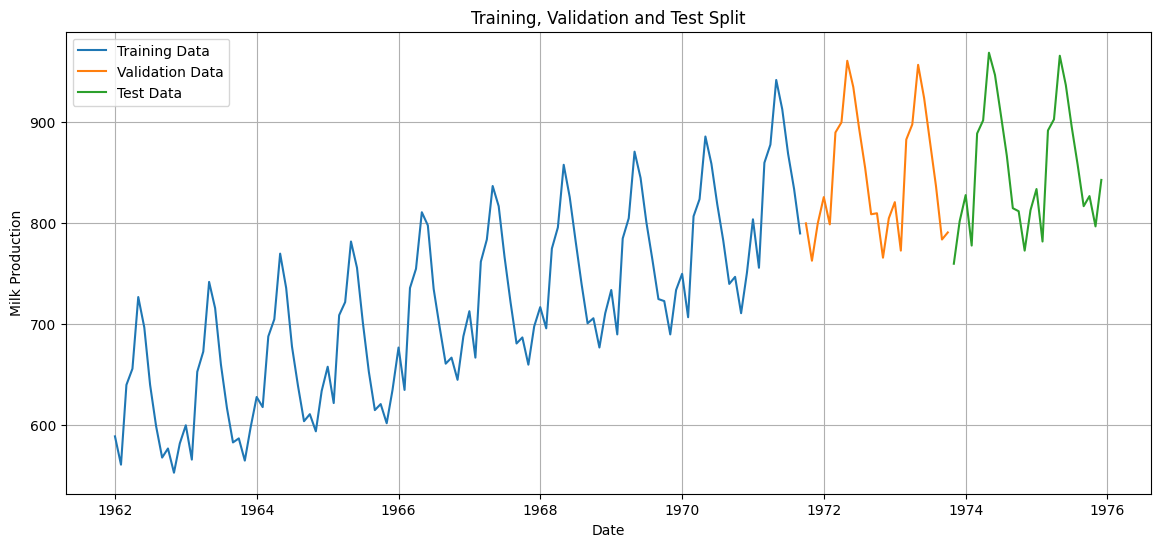

In [33]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Plot the complete time series.
# ---------------------------------------------------------

plt.figure(figsize=(14, 6))

# Plot training data.
plt.plot(
    train_data['Date'],
    train_data['Production'],
    label='Training Data'
)

# Plot validation data.
plt.plot(
    val_data['Date'],
    val_data['Production'],
    label='Validation Data'
)

# Plot testing data.
plt.plot(
    test_data['Date'],
    test_data['Production'],
    label='Test Data'
)

plt.title('Training, Validation and Test Split')
plt.xlabel('Date')
plt.ylabel('Milk Production')

plt.legend()
plt.grid(True)

plt.show()

# 3.Model Building

In [34]:
# ---------------------------------------------------------
# Define the main hyperparameters.
#
# The window size was already selected as 12 months in the
# previous task because the data contains monthly observations.
# ---------------------------------------------------------

window_size = 12

# Number of neurons in the recurrent layer
units = 64

# Number of samples processed before updating model weights
batch_size = 16

# Maximum number of complete passes through the training data
epochs = 100

# Learning rate used by the Adam optimizer
learning_rate = 0.001

print("Window size:", window_size)
print("Units:", units)
print("Batch size:", batch_size)
print("Epochs:", epochs)
print("Learning rate:", learning_rate)

Window size: 12
Units: 64
Batch size: 16
Epochs: 100
Learning rate: 0.001


In [35]:
# ---------------------------------------------------------
# Create the Basic RNN model.
# ---------------------------------------------------------

rnn_model = Sequential()

# ---------------------------------------------------------
# SimpleRNN receives 12 time steps and 1 feature at each
# time step.
#
# The 64 units allow the model to learn patterns from the
# historical milk production values.
# ---------------------------------------------------------

rnn_model.add(
    SimpleRNN(
        units=units,
        activation='tanh',
        input_shape=(window_size, 1)
    )
)

# ---------------------------------------------------------
# Dense layer produces the final milk production prediction.
#
# One neuron is used because we are predicting one numerical
# value for the next month.
# ---------------------------------------------------------

rnn_model.add(Dense(1))

# ---------------------------------------------------------
# Compile the model.
#
# Mean Squared Error is used as the loss function because
# this is a regression problem.
#
# Adam is used as the optimizer because it generally works
# well for neural network training.
# ---------------------------------------------------------

rnn_model.compile(
    optimizer=Adam(learning_rate=learning_rate),
    loss='mse',
    metrics=['mae']
)

# Display the model architecture.
rnn_model.summary()

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)               │ (None, 64)                  │           4,224 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,289 (16.75 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
# ---------------------------------------------------------
# EarlyStopping monitors validation loss.
#
# If validation loss does not improve for 15 consecutive
# epochs, training will stop.
#
# restore_best_weights=True restores the weights from the
# epoch that produced the best validation performance.
# ---------------------------------------------------------

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

# ---------------------------------------------------------
# Train the Basic RNN model.
#
# shuffle=False is important for time series because we want
# to preserve the chronological order of observations.
# ---------------------------------------------------------

rnn_history = rnn_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - loss: 0.7777 - mae: 0.7167 - val_loss: 1.2106 - val_mae: 0.9151
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.2013 - mae: 0.3622 - val_loss: 0.4904 - val_mae: 0.5555
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.2279 - mae: 0.3869 - val_loss: 0.4276 - val_mae: 0.5232
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1595 - mae: 0.3149 - val_loss: 0.5167 - val_mae: 0.5712
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.1068 - mae: 0.2511 - val_loss: 0.5141 - val_mae: 0.5775
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 0.0840 - mae: 0.2189 - val_loss: 0.3926 - val_mae: 0.5023
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0687 - mae: 0.2034 - val_loss: 0.2855 - val_mae: 0.4321
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0621 - mae: 0.1928 - val_loss: 0.2454 - val_mae: 0.4033
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0516 - mae: 

In [37]:
# ---------------------------------------------------------
# Create the LSTM model.
# ---------------------------------------------------------

lstm_model = Sequential()

# ---------------------------------------------------------
# Add the LSTM layer.
#
# The LSTM receives 12 months of historical information.
#
# 64 units are used to provide enough capacity to learn
# temporal patterns.
# ---------------------------------------------------------

lstm_model.add(
    LSTM(
        units=units,
        activation='tanh',
        input_shape=(window_size, 1)
    )
)

# ---------------------------------------------------------
# Add the output layer.
#
# One neuron is used because we predict one production value.
# ---------------------------------------------------------

lstm_model.add(Dense(1))

# ---------------------------------------------------------
# Compile the LSTM model.
# ---------------------------------------------------------

lstm_model.compile(
    optimizer=Adam(learning_rate=learning_rate),
    loss='mse',
    metrics=['mae']
)

# Display the model structure.
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# ---------------------------------------------------------
# Train the LSTM model using the same training and validation
# datasets.
#
# Using the same datasets makes the comparison between the
# models more meaningful.
# ---------------------------------------------------------

lstm_history = lstm_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - loss: 0.8477 - mae: 0.7460 - val_loss: 1.8743 - val_mae: 1.1864
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6769 - mae: 0.6735 - val_loss: 1.0913 - val_mae: 0.8121
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.5697 - mae: 0.6385 - val_loss: 0.5843 - val_mae: 0.6024
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.5110 - mae: 0.6245 - val_loss: 0.4878 - val_mae: 0.6292
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.5045 - mae: 0.6199 - val_loss: 0.6509 - val_mae: 0.6848
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.4838 - mae: 0.6003 - val_loss: 0.5699 - val_mae: 0.6462
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.4406 - mae: 0.5764 - val_loss: 0.4413 - val_mae: 0.5896
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.4070 - mae: 0.5529 - val_loss: 0.4095 - val_mae: 0.5667
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.3752 - mae: 

In [39]:
# ---------------------------------------------------------
# Create the GRU model.
# ---------------------------------------------------------

gru_model = Sequential()

# ---------------------------------------------------------
# Add the GRU layer.
#
# 64 units are used.
#
# The model receives 12 months of historical production
# information at each training step.
# ---------------------------------------------------------

gru_model.add(
    GRU(
        units=units,
        activation='tanh',
        input_shape=(window_size, 1)
    )
)

# ---------------------------------------------------------
# Add the output layer.
# ---------------------------------------------------------

gru_model.add(Dense(1))

# ---------------------------------------------------------
# Compile the GRU model.
# ---------------------------------------------------------

gru_model.compile(
    optimizer=Adam(learning_rate=learning_rate),
    loss='mse',
    metrics=['mae']
)

# Display the model architecture.
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ gru (GRU)                            │ (None, 64)                  │          12,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,929 (50.50 KB)

 Trainable params: 12,929 (50.50 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# ---------------------------------------------------------
# Train the GRU model.
# ---------------------------------------------------------

gru_history = gru_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=epochs,
    batch_size=batch_size,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 1.0482 - mae: 0.8270 - val_loss: 2.5759 - val_mae: 1.4345
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.8048 - mae: 0.7298 - val_loss: 1.6668 - val_mae: 1.0743
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.6671 - mae: 0.6757 - val_loss: 1.0692 - val_mae: 0.7916
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5921 - mae: 0.6503 - val_loss: 0.7358 - val_mae: 0.6591
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5572 - mae: 0.6427 - val_loss: 0.5838 - val_mae: 0.6109
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.5378 - mae: 0.6379 - val_loss: 0.5202 - val_mae: 0.5970
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.5171 - mae: 0.6281 - val_loss: 0.4848 - val_mae: 0.5769
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.4922 - mae: 0.6136 - val_loss: 0.4604 - val_mae: 0.5522
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.4668 - mae: 

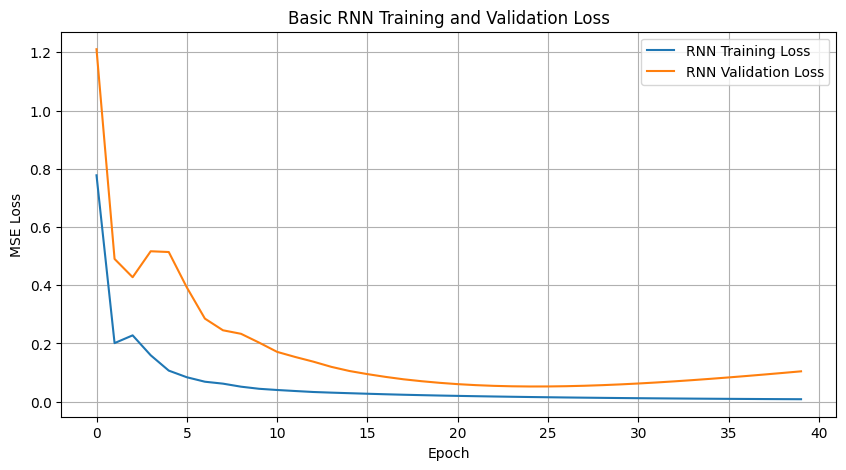

In [41]:
# ---------------------------------------------------------
# Plot the training and validation loss of the Basic RNN.
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    rnn_history.history['loss'],
    label='RNN Training Loss'
)

plt.plot(
    rnn_history.history['val_loss'],
    label='RNN Validation Loss'
)

plt.title('Basic RNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.show()

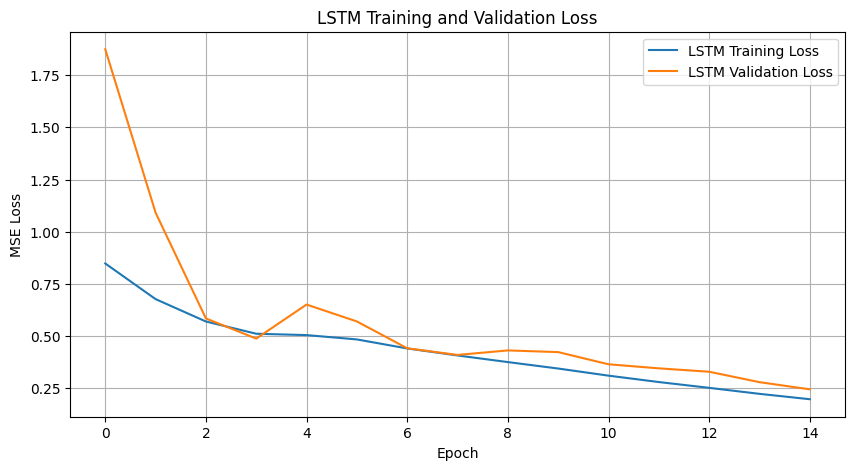

In [42]:
# ---------------------------------------------------------
# Plot the training and validation loss of the LSTM.
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    lstm_history.history['loss'],
    label='LSTM Training Loss'
)

plt.plot(
    lstm_history.history['val_loss'],
    label='LSTM Validation Loss'
)

plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.show()

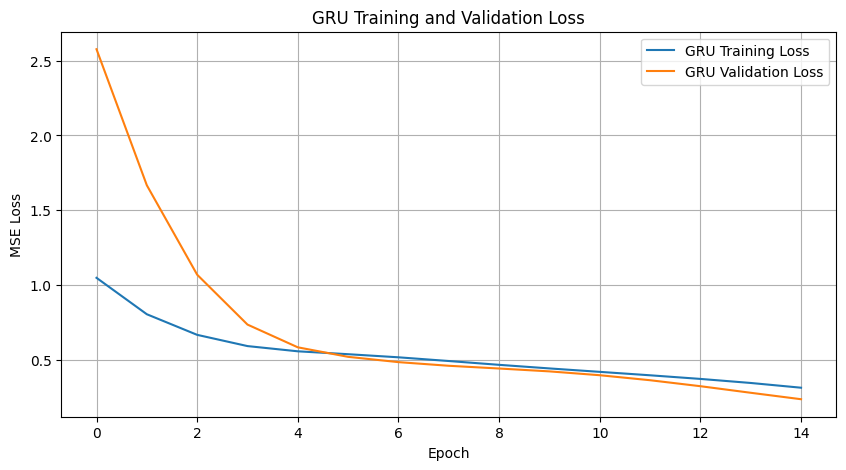

In [43]:
# ---------------------------------------------------------
# Plot the training and validation loss of the GRU.
# ---------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    gru_history.history['loss'],
    label='GRU Training Loss'
)

plt.plot(
    gru_history.history['val_loss'],
    label='GRU Validation Loss'
)

plt.title('GRU Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.legend()
plt.grid(True)

plt.show()

In [44]:
# ---------------------------------------------------------
# Test different numbers of recurrent units.
#
# We will compare 32, 64 and 128 units.
# ---------------------------------------------------------

unit_values = [32, 64, 128]

rnn_tuning_results = []

for current_units in unit_values:
    
    # -----------------------------------------------------
    # Create a new RNN model for the current number of units.
    # -----------------------------------------------------
    
    model = Sequential([
        SimpleRNN(
            current_units,
            activation='tanh',
            input_shape=(window_size, 1)
        ),
        Dense(1)
    ])
    
    # -----------------------------------------------------
    # Compile the model using MSE loss and Adam optimizer.
    # -----------------------------------------------------
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    
    # -----------------------------------------------------
    # Train the model.
    #
    # A smaller number of epochs is used during tuning so
    # that different configurations can be compared faster.
    # -----------------------------------------------------
    
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=batch_size,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )
    
    # -----------------------------------------------------
    # Store the best validation loss obtained by this model.
    # -----------------------------------------------------
    
    best_val_loss = min(history.history['val_loss'])
    
    rnn_tuning_results.append({
        'Units': current_units,
        'Best Validation Loss': best_val_loss
    })


# ---------------------------------------------------------
# Convert tuning results into a DataFrame.
# ---------------------------------------------------------

tuning_df = pd.DataFrame(rnn_tuning_results)

print(tuning_df)

   Units  Best Validation Loss
0     32              0.121179
1     64              0.052346
2    128              0.063369


In [45]:
# ---------------------------------------------------------
# Test different batch sizes.
# ---------------------------------------------------------

batch_values = [8, 16, 32]

batch_results = []

for current_batch in batch_values:
    
    # -----------------------------------------------------
    # Create the RNN model.
    # -----------------------------------------------------
    
    model = Sequential([
        SimpleRNN(
            64,
            activation='tanh',
            input_shape=(window_size, 1)
        ),
        Dense(1)
    ])
    
    # -----------------------------------------------------
    # Compile the model.
    # -----------------------------------------------------
    
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    
    # -----------------------------------------------------
    # Train the model using the current batch size.
    # -----------------------------------------------------
    
    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=current_batch,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )
    
    # -----------------------------------------------------
    # Store the best validation loss.
    # -----------------------------------------------------
    
    best_val_loss = min(history.history['val_loss'])
    
    batch_results.append({
        'Batch Size': current_batch,
        'Best Validation Loss': best_val_loss
    })


# ---------------------------------------------------------
# Display the results.
# ---------------------------------------------------------

batch_df = pd.DataFrame(batch_results)

print(batch_df)

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Batch Size  Best Validation Loss
0           8              0.050227
1          16              0.059283
2          32              0.056926


In [47]:
# ---------------------------------------------------------
# Function for creating datasets for a selected window size.
# ---------------------------------------------------------

def prepare_sequences_for_window(window):
    
    # Create training sequences
    X_train_temp, y_train_temp = create_sequences(
        train_scaled,
        window
    )
    
    # Create validation sequences using historical training
    # observations as context
    val_input_temp = np.concatenate(
        [train_scaled[-window:], val_scaled]
    )
    
    X_val_temp, y_val_temp = create_sequences(
        val_input_temp,
        window
    )
    
    # Create test sequences using historical validation
    # observations as context
    test_input_temp = np.concatenate(
        [val_scaled[-window:], test_scaled]
    )
    
    X_test_temp, y_test_temp = create_sequences(
        test_input_temp,
        window
    )
    
    return (
        X_train_temp,
        y_train_temp,
        X_val_temp,
        y_val_temp,
        X_test_temp,
        y_test_temp
    )

In [48]:
# ---------------------------------------------------------
# Compare different historical window sizes.
# ---------------------------------------------------------

window_values = [6, 12, 18]

window_results = []

for current_window in window_values:
    
    # Prepare sequences using the current window.
    (
        X_train_temp,
        y_train_temp,
        X_val_temp,
        y_val_temp,
        X_test_temp,
        y_test_temp
    ) = prepare_sequences_for_window(current_window)
    
    # -----------------------------------------------------
    # Create an RNN model.
    # -----------------------------------------------------
    
    model = Sequential([
        SimpleRNN(
            64,
            activation='tanh',
            input_shape=(current_window, 1)
        ),
        Dense(1)
    ])
    
    # Compile the model.
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )
    
    # Train the model.
    history = model.fit(
        X_train_temp,
        y_train_temp,
        validation_data=(X_val_temp, y_val_temp),
        epochs=50,
        batch_size=16,
        shuffle=False,
        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=10,
                restore_best_weights=True
            )
        ],
        verbose=0
    )
    
    # Store the best validation loss.
    best_val_loss = min(history.history['val_loss'])
    
    window_results.append({
        'Window Size': current_window,
        'Best Validation Loss': best_val_loss
    })


# ---------------------------------------------------------
# Display window size comparison.
# ---------------------------------------------------------

window_df = pd.DataFrame(window_results)

print(window_df)

C:\Users\BALAJI\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


   Window Size  Best Validation Loss
0            6              0.230846
1           12              0.041043
2           18              0.061117


In [49]:
# ---------------------------------------------------------
# Find the lowest validation loss achieved by each model.
# ---------------------------------------------------------

rnn_best_loss = min(
    rnn_history.history['val_loss']
)

lstm_best_loss = min(
    lstm_history.history['val_loss']
)

gru_best_loss = min(
    gru_history.history['val_loss']
)


# ---------------------------------------------------------
# Create a comparison DataFrame.
# ---------------------------------------------------------

model_comparison = pd.DataFrame({
    'Model': [
        'Basic RNN',
        'LSTM',
        'GRU'
    ],
    
    'Best Validation Loss': [
        rnn_best_loss,
        lstm_best_loss,
        gru_best_loss
    ]
})


# ---------------------------------------------------------
# Display the comparison.
# ---------------------------------------------------------

print(model_comparison)

       Model  Best Validation Loss
0  Basic RNN              0.052325
1       LSTM              0.244679
2        GRU              0.236930


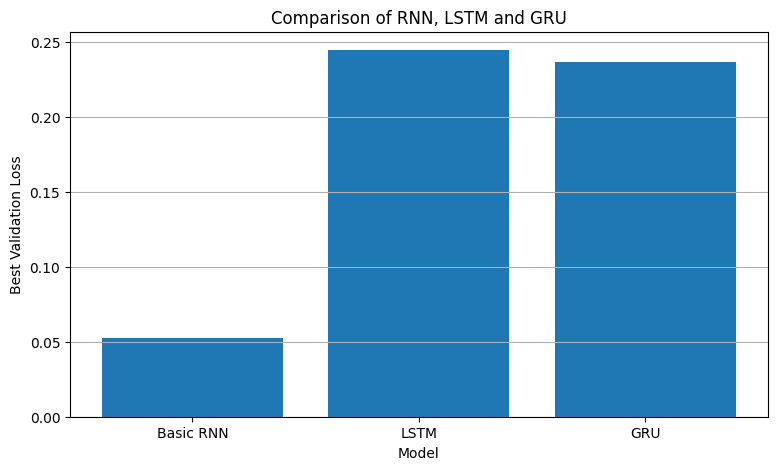

In [50]:
# ---------------------------------------------------------
# Plot validation loss comparison.
# ---------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    model_comparison['Model'],
    model_comparison['Best Validation Loss']
)

plt.title('Comparison of RNN, LSTM and GRU')
plt.xlabel('Model')
plt.ylabel('Best Validation Loss')

plt.grid(axis='y')

plt.show()

# Prediction and Visualization

In [51]:
# ---------------------------------------------------------
# Check that the three trained models are available.
# ---------------------------------------------------------

print("RNN model:", rnn_model)
print("LSTM model:", lstm_model)
print("GRU model:", gru_model)

# ---------------------------------------------------------
# The models were trained using a 12 month input window.
# Therefore, the final 12 months of historical data will
# be used as the starting input for future forecasting.
# ---------------------------------------------------------

RNN model: <Sequential name=sequential, built=True>
LSTM model: <Sequential name=sequential_1, built=True>
GRU model: <Sequential name=sequential_2, built=True>


In [52]:
# ---------------------------------------------------------
# Select the final 12 scaled production observations.
#
# These values represent the most recent one year of
# historical milk production.
# ---------------------------------------------------------

last_window = train_scaled

# ---------------------------------------------------------
# Important:
#
# train_scaled contains only training data from the previous
# split, so for final future forecasting we need the complete
# dataset scaled using the training scaler.
#
# We therefore transform the complete historical production
# data using the scaler that was fitted on training data.
# ---------------------------------------------------------

all_scaled = scaler.transform(
    df[['Production']]
)

# ---------------------------------------------------------
# Select the last 12 months from the complete dataset.
# ---------------------------------------------------------

last_window = all_scaled[-window_size:]

print("Shape of last window:", last_window.shape)

print("\nLast 12 scaled observations:")
print(last_window)

Shape of last window: (12, 1)

Last 12 scaled observations:
[[1.3898363 ]
 [0.79284646]
 [2.05570957]
 [2.18199588]
 [2.90527203]
 [2.57233539]
 [2.10163187]
 [1.66537007]
 [1.19466654]
 [1.30947228]
 [0.96505507]
 [1.49316146]]


In [53]:
# ---------------------------------------------------------
# Reshape the last 12 months so that it can be given to
# the neural network.
#
# 1 represents one input sequence.
# 12 represents twelve historical months.
# 1 represents the Production feature.
# ---------------------------------------------------------

current_window = last_window.reshape(
    1,
    window_size,
    1
)

print("Input shape for forecasting:", current_window.shape)

Input shape for forecasting: (1, 12, 1)


In [54]:
# ---------------------------------------------------------
# Create an empty list to store the future predictions.
# ---------------------------------------------------------

lstm_future_scaled = []

# ---------------------------------------------------------
# Make a copy of the current 12 month window.
# ---------------------------------------------------------

current_window = last_window.copy()

# ---------------------------------------------------------
# Generate predictions one month at a time.
# ---------------------------------------------------------

for i in range(12):
    
    # -----------------------------------------------------
    # Reshape the current window into the format expected
    # by the LSTM model.
    # -----------------------------------------------------
    
    model_input = current_window.reshape(
        1,
        window_size,
        1
    )
    
    # -----------------------------------------------------
    # Predict the next month's scaled production.
    # -----------------------------------------------------
    
    next_prediction = lstm_model.predict(
        model_input,
        verbose=0
    )[0, 0]
    
    # -----------------------------------------------------
    # Store the prediction.
    # -----------------------------------------------------
    
    lstm_future_scaled.append(
        next_prediction
    )
    
    # -----------------------------------------------------
    # Add the new prediction to the end of the window.
    #
    # The oldest observation is removed because the model
    # always uses the most recent 12 months.
    # -----------------------------------------------------
    
    current_window = np.append(
        current_window[1:],
        [[next_prediction]],
        axis=0
    )

# ---------------------------------------------------------
# Convert the predictions into a NumPy array.
# ---------------------------------------------------------

lstm_future_scaled = np.array(
    lstm_future_scaled
).reshape(-1, 1)

print("Scaled future predictions:")
print(lstm_future_scaled)

Scaled future predictions:
[[0.36218444]
 [0.31634548]
 [0.28172842]
 [0.24108657]
 [0.20157455]
 [0.16026458]
 [0.12386926]
 [0.09344289]
 [0.06862047]
 [0.04929558]
 [0.03115048]
 [0.01716979]]


In [55]:
# ---------------------------------------------------------
# Create an empty list to store the future predictions.
# ---------------------------------------------------------

lstm_future_scaled = []

# ---------------------------------------------------------
# Make a copy of the current 12 month window.
# ---------------------------------------------------------

current_window = last_window.copy()

# ---------------------------------------------------------
# Generate predictions one month at a time.
# ---------------------------------------------------------

for i in range(12):
    
    # -----------------------------------------------------
    # Reshape the current window into the format expected
    # by the LSTM model.
    # -----------------------------------------------------
    
    model_input = current_window.reshape(
        1,
        window_size,
        1
    )
    
    # -----------------------------------------------------
    # Predict the next month's scaled production.
    # -----------------------------------------------------
    
    next_prediction = lstm_model.predict(
        model_input,
        verbose=0
    )[0, 0]
    
    # -----------------------------------------------------
    # Store the prediction.
    # -----------------------------------------------------
    
    lstm_future_scaled.append(
        next_prediction
    )
    
    # -----------------------------------------------------
    # Add the new prediction to the end of the window.
    #
    # The oldest observation is removed because the model
    # always uses the most recent 12 months.
    # -----------------------------------------------------
    
    current_window = np.append(
        current_window[1:],
        [[next_prediction]],
        axis=0
    )

# ---------------------------------------------------------
# Convert the predictions into a NumPy array.
# ---------------------------------------------------------

lstm_future_scaled = np.array(
    lstm_future_scaled
).reshape(-1, 1)

print("Scaled future predictions:")
print(lstm_future_scaled)

Scaled future predictions:
[[0.36218444]
 [0.31634548]
 [0.28172842]
 [0.24108657]
 [0.20157455]
 [0.16026458]
 [0.12386926]
 [0.09344289]
 [0.06862047]
 [0.04929558]
 [0.03115048]
 [0.01716979]]


In [58]:
# ---------------------------------------------------------
# Convert the scaled LSTM predictions back to the original
# milk production scale.
# ---------------------------------------------------------

lstm_future = scaler.inverse_transform(
    lstm_future_scaled
)

# Convert the two dimensional array into a one dimensional
# array for easier handling.
lstm_future = lstm_future.flatten()

print("LSTM forecast for the next 12 months:")
print(lstm_future)

LSTM forecast for the next 12 months:
[744.48773 740.495   737.47974 733.9397  730.49805 726.8998  723.7296
 721.0794  718.91724 717.234   715.6535  714.4357 ]


In [59]:
# ---------------------------------------------------------
# Find the last date available in the historical dataset.
# ---------------------------------------------------------

last_date = df['Date'].max()

# ---------------------------------------------------------
# Create the next 12 monthly dates.
#
# Month Start is used because the original dataset stores
# monthly observations in YYYY-MM format.
# ---------------------------------------------------------

future_dates = pd.date_range(
    start=last_date + pd.offsets.MonthBegin(1),
    periods=12,
    freq='MS'
)

# ---------------------------------------------------------
# Display the future dates.
# ---------------------------------------------------------

print("Future forecast dates:")
print(future_dates)

Future forecast dates:
DatetimeIndex(['1976-01-01', '1976-02-01', '1976-03-01', '1976-04-01',
               '1976-05-01', '1976-06-01', '1976-07-01', '1976-08-01',
               '1976-09-01', '1976-10-01', '1976-11-01', '1976-12-01'],
              dtype='datetime64[ns]', freq='MS')


In [60]:
# ---------------------------------------------------------
# Create a DataFrame containing the future dates and
# corresponding LSTM predictions.
# ---------------------------------------------------------

lstm_forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Predicted_Production': lstm_future
})

# ---------------------------------------------------------
# Display the forecast.
# ---------------------------------------------------------

print(lstm_forecast_df)

         Date  Predicted_Production
0  1976-01-01            744.487732
1  1976-02-01            740.494995
2  1976-03-01            737.479736
3  1976-04-01            733.939697
4  1976-05-01            730.498047
5  1976-06-01            726.899780
6  1976-07-01            723.729614
7  1976-08-01            721.079407
8  1976-09-01            718.917236
9  1976-10-01            717.234009
10 1976-11-01            715.653503
11 1976-12-01            714.435730


In [61]:
# ---------------------------------------------------------
# Create an empty list for RNN future predictions.
# ---------------------------------------------------------

rnn_future_scaled = []

# ---------------------------------------------------------
# Start with the final 12 months of historical data.
# ---------------------------------------------------------

current_window = last_window.copy()

# ---------------------------------------------------------
# Generate 12 future predictions.
# ---------------------------------------------------------

for i in range(12):
    
    # Reshape the input for the RNN.
    model_input = current_window.reshape(
        1,
        window_size,
        1
    )
    
    # Predict the next month.
    next_prediction = rnn_model.predict(
        model_input,
        verbose=0
    )[0, 0]
    
    # Store the prediction.
    rnn_future_scaled.append(
        next_prediction
    )
    
    # Update the rolling window.
    current_window = np.append(
        current_window[1:],
        [[next_prediction]],
        axis=0
    )

# ---------------------------------------------------------
# Convert predictions to two dimensional format.
# ---------------------------------------------------------

rnn_future_scaled = np.array(
    rnn_future_scaled
).reshape(-1, 1)

# ---------------------------------------------------------
# Convert predictions back to the original production scale.
# ---------------------------------------------------------

rnn_future = scaler.inverse_transform(
    rnn_future_scaled
).flatten()

print("RNN forecast:")
print(rnn_future)

RNN forecast:
[822.57367 805.85046 868.5923  880.40076 938.80133 927.82    903.5332
 884.77985 852.449   850.073   825.2237  826.0612 ]


In [62]:
# ---------------------------------------------------------
# Create an empty list for GRU future predictions.
# ---------------------------------------------------------

gru_future_scaled = []

# ---------------------------------------------------------
# Start with the final 12 months of historical observations.
# ---------------------------------------------------------

current_window = last_window.copy()

# ---------------------------------------------------------
# Generate predictions recursively for the next 12 months.
# ---------------------------------------------------------

for i in range(12):
    
    # Reshape the current window for the GRU.
    model_input = current_window.reshape(
        1,
        window_size,
        1
    )
    
    # Predict the next month's production.
    next_prediction = gru_model.predict(
        model_input,
        verbose=0
    )[0, 0]
    
    # Store the prediction.
    gru_future_scaled.append(
        next_prediction
    )
    
    # Update the rolling window.
    current_window = np.append(
        current_window[1:],
        [[next_prediction]],
        axis=0
    )

# ---------------------------------------------------------
# Convert predictions to two dimensional format.
# ---------------------------------------------------------

gru_future_scaled = np.array(
    gru_future_scaled
).reshape(-1, 1)

# ---------------------------------------------------------
# Convert the scaled predictions back to the original scale.
# ---------------------------------------------------------

gru_future = scaler.inverse_transform(
    gru_future_scaled
).flatten()

print("GRU forecast:")
print(gru_future)

GRU forecast:
[721.4951  723.6576  720.88464 717.62225 714.98096 713.0168  711.6267
 710.6591  709.9907  709.5343  709.2098  708.9922 ]


In [63]:
# ---------------------------------------------------------
# Create a DataFrame containing predictions from all three
# models.
# ---------------------------------------------------------

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'RNN': rnn_future,
    'LSTM': lstm_future,
    'GRU': gru_future
})

# ---------------------------------------------------------
# Display the complete 12 month forecast.
# ---------------------------------------------------------

print(forecast_df)

         Date         RNN        LSTM         GRU
0  1976-01-01  822.573669  744.487732  721.495117
1  1976-02-01  805.850464  740.494995  723.657593
2  1976-03-01  868.592285  737.479736  720.884644
3  1976-04-01  880.400757  733.939697  717.622253
4  1976-05-01  938.801331  730.498047  714.980957
5  1976-06-01  927.820007  726.899780  713.016785
6  1976-07-01  903.533203  723.729614  711.626709
7  1976-08-01  884.779846  721.079407  710.659119
8  1976-09-01  852.448975  718.917236  709.990723
9  1976-10-01  850.072998  717.234009  709.534302
10 1976-11-01  825.223694  715.653503  709.209778
11 1976-12-01  826.061218  714.435730  708.992188


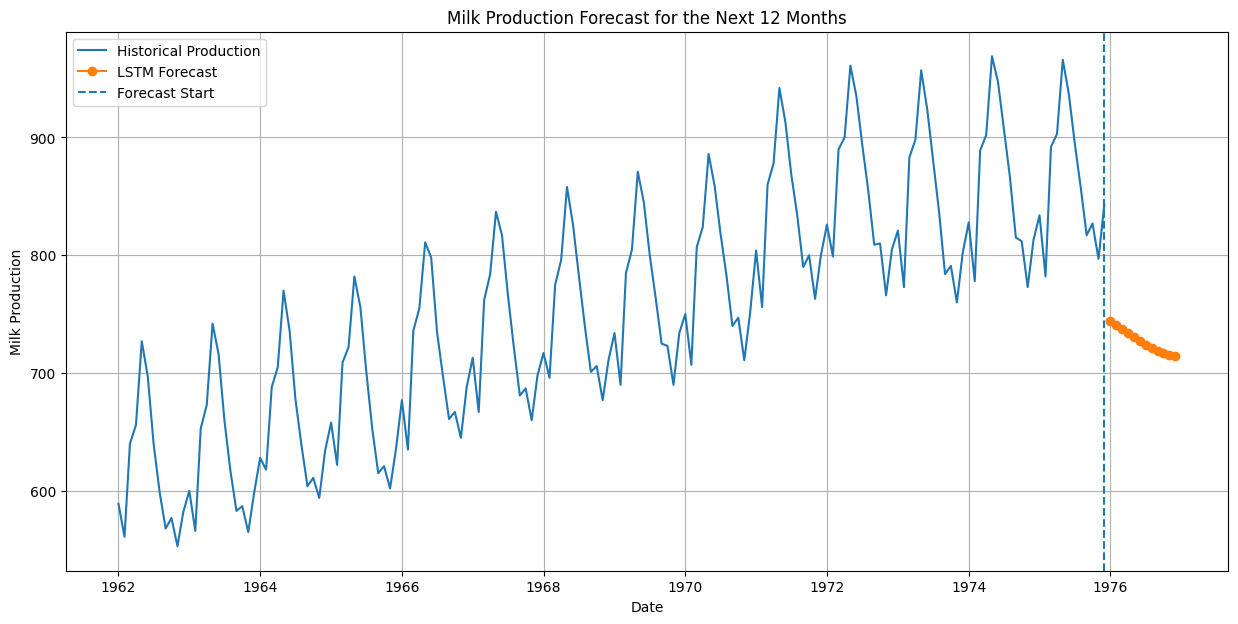

In [64]:
# ---------------------------------------------------------
# Plot historical milk production.
# ---------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    df['Date'],
    df['Production'],
    label='Historical Production'
)

# ---------------------------------------------------------
# Plot the LSTM predictions.
# ---------------------------------------------------------

plt.plot(
    forecast_df['Date'],
    forecast_df['LSTM'],
    marker='o',
    label='LSTM Forecast'
)

# ---------------------------------------------------------
# Add a vertical line to indicate where forecasting begins.
# ---------------------------------------------------------

plt.axvline(
    x=df['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title('Milk Production Forecast for the Next 12 Months')

plt.xlabel('Date')

plt.ylabel('Milk Production')

plt.legend()

plt.grid(True)

plt.show()

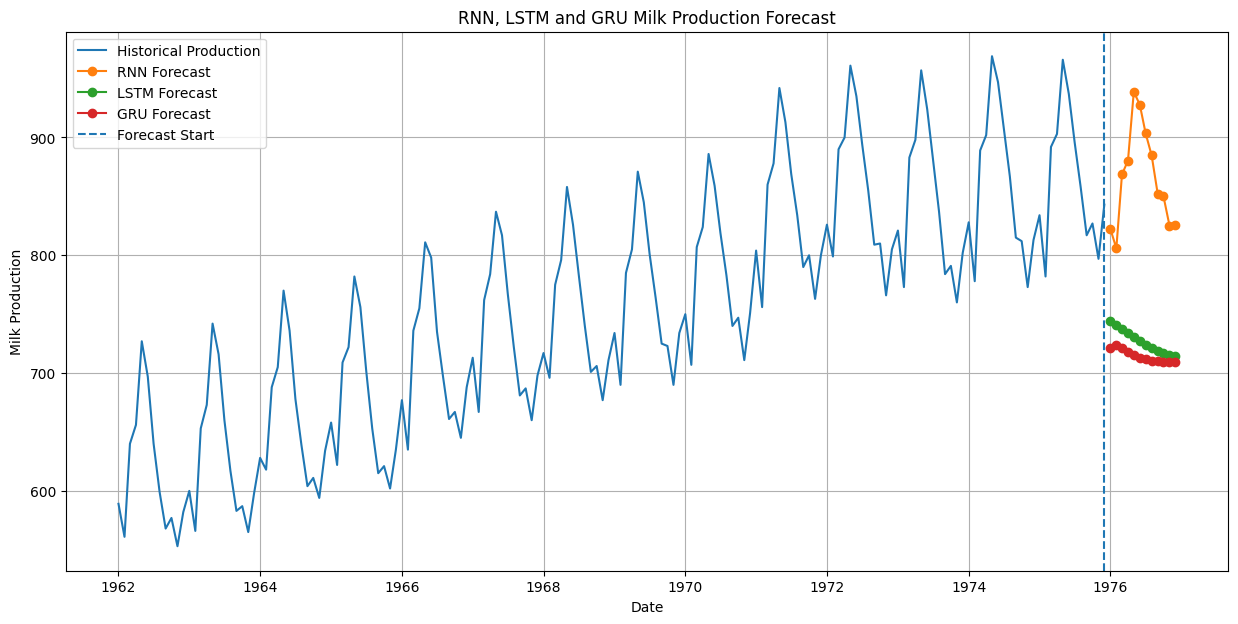

In [65]:
# ---------------------------------------------------------
# Plot all three model forecasts together.
# ---------------------------------------------------------

plt.figure(figsize=(15, 7))

# Historical production
plt.plot(
    df['Date'],
    df['Production'],
    label='Historical Production'
)

# RNN forecast
plt.plot(
    forecast_df['Date'],
    forecast_df['RNN'],
    marker='o',
    label='RNN Forecast'
)

# LSTM forecast
plt.plot(
    forecast_df['Date'],
    forecast_df['LSTM'],
    marker='o',
    label='LSTM Forecast'
)

# GRU forecast
plt.plot(
    forecast_df['Date'],
    forecast_df['GRU'],
    marker='o',
    label='GRU Forecast'
)

# Show the point where historical observations end.
plt.axvline(
    x=df['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title(
    'RNN, LSTM and GRU Milk Production Forecast'
)

plt.xlabel('Date')

plt.ylabel('Milk Production')

plt.legend()

plt.grid(True)

plt.show()

In [66]:
# ---------------------------------------------------------
# Generate LSTM predictions on the test dataset.
# ---------------------------------------------------------

lstm_test_scaled = lstm_model.predict(
    X_test,
    verbose=0
)

# ---------------------------------------------------------
# Convert the predictions back to the original production
# scale.
# ---------------------------------------------------------

lstm_test_predictions = scaler.inverse_transform(
    lstm_test_scaled
).flatten()

# ---------------------------------------------------------
# Convert the actual test values back to the original scale.
# ---------------------------------------------------------

lstm_test_actual = scaler.inverse_transform(
    y_test
).flatten()

# ---------------------------------------------------------
# Calculate the prediction errors.
# ---------------------------------------------------------

lstm_errors = (
    lstm_test_actual -
    lstm_test_predictions
)

# ---------------------------------------------------------
# Calculate the standard deviation of the errors.
# ---------------------------------------------------------

error_std = np.std(lstm_errors)

print("LSTM test error standard deviation:", error_std)

LSTM test error standard deviation: 59.8977325068558


In [67]:
# ---------------------------------------------------------
# Calculate an approximate 95 percent prediction interval.
#
# 1.96 is used as an approximate multiplier for a 95 percent
# interval under a normal error assumption.
#
# This is an approximate uncertainty interval and should not
# be interpreted as a formal confidence interval.
# ---------------------------------------------------------

forecast_df['Lower_Bound'] = (
    forecast_df['LSTM'] -
    1.96 * error_std
)

forecast_df['Upper_Bound'] = (
    forecast_df['LSTM'] +
    1.96 * error_std
)

# ---------------------------------------------------------
# Display the forecast with uncertainty bounds.
# ---------------------------------------------------------

print(
    forecast_df[
        [
            'Date',
            'LSTM',
            'Lower_Bound',
            'Upper_Bound'
        ]
    ]
)

         Date        LSTM  Lower_Bound  Upper_Bound
0  1976-01-01  744.487732   627.088196   861.887268
1  1976-02-01  740.494995   623.095459   857.894531
2  1976-03-01  737.479736   620.080200   854.879272
3  1976-04-01  733.939697   616.540161   851.339233
4  1976-05-01  730.498047   613.098511   847.897583
5  1976-06-01  726.899780   609.500244   844.299316
6  1976-07-01  723.729614   606.330078   841.129150
7  1976-08-01  721.079407   603.679871   838.478943
8  1976-09-01  718.917236   601.517700   836.316772
9  1976-10-01  717.234009   599.834473   834.633545
10 1976-11-01  715.653503   598.253967   833.053040
11 1976-12-01  714.435730   597.036194   831.835266


In [68]:
# ---------------------------------------------------------
# Ensure that the lower prediction bound cannot become
# negative.
# ---------------------------------------------------------

forecast_df['Lower_Bound'] = forecast_df[
    'Lower_Bound'
].clip(lower=0)

print(
    forecast_df[
        [
            'Date',
            'LSTM',
            'Lower_Bound',
            'Upper_Bound'
        ]
    ]
)

         Date        LSTM  Lower_Bound  Upper_Bound
0  1976-01-01  744.487732   627.088196   861.887268
1  1976-02-01  740.494995   623.095459   857.894531
2  1976-03-01  737.479736   620.080200   854.879272
3  1976-04-01  733.939697   616.540161   851.339233
4  1976-05-01  730.498047   613.098511   847.897583
5  1976-06-01  726.899780   609.500244   844.299316
6  1976-07-01  723.729614   606.330078   841.129150
7  1976-08-01  721.079407   603.679871   838.478943
8  1976-09-01  718.917236   601.517700   836.316772
9  1976-10-01  717.234009   599.834473   834.633545
10 1976-11-01  715.653503   598.253967   833.053040
11 1976-12-01  714.435730   597.036194   831.835266


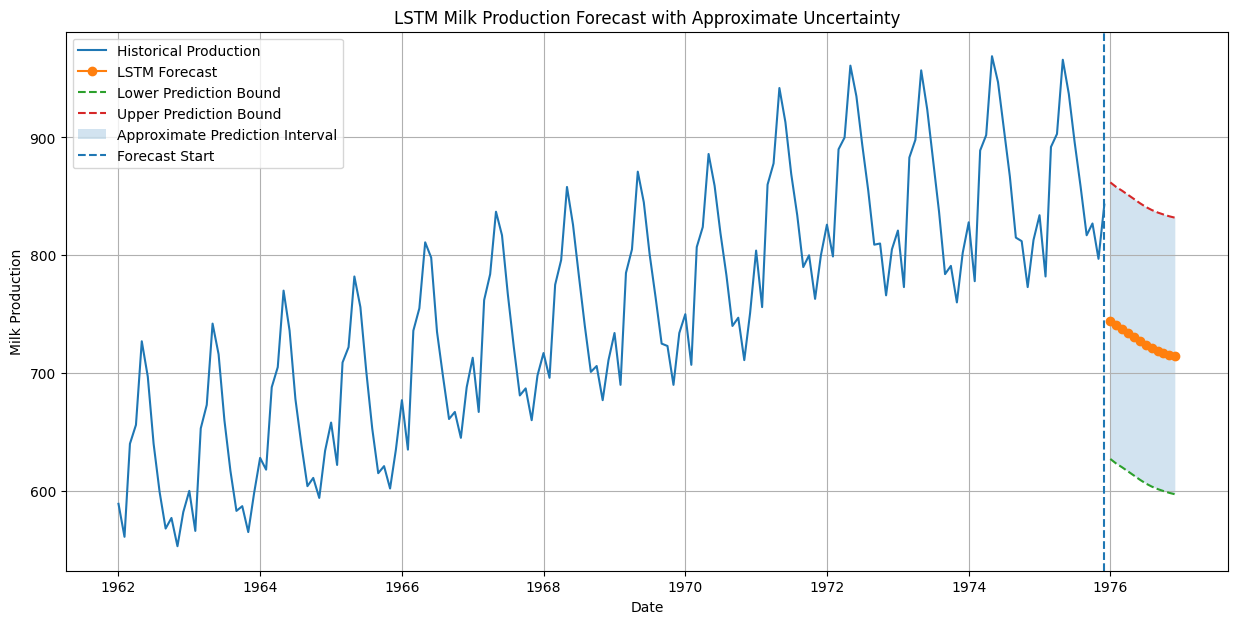

In [69]:
# ---------------------------------------------------------
# Create the forecast visualization.
# ---------------------------------------------------------

plt.figure(figsize=(15, 7))

# ---------------------------------------------------------
# Plot the historical production.
# ---------------------------------------------------------

plt.plot(
    df['Date'],
    df['Production'],
    label='Historical Production'
)

# ---------------------------------------------------------
# Plot the LSTM forecast.
# ---------------------------------------------------------

plt.plot(
    forecast_df['Date'],
    forecast_df['LSTM'],
    marker='o',
    label='LSTM Forecast'
)

# ---------------------------------------------------------
# Plot the lower uncertainty boundary.
# ---------------------------------------------------------

plt.plot(
    forecast_df['Date'],
    forecast_df['Lower_Bound'],
    linestyle='--',
    label='Lower Prediction Bound'
)

# ---------------------------------------------------------
# Plot the upper uncertainty boundary.
# ---------------------------------------------------------

plt.plot(
    forecast_df['Date'],
    forecast_df['Upper_Bound'],
    linestyle='--',
    label='Upper Prediction Bound'
)

# ---------------------------------------------------------
# Shade the area between the lower and upper bounds.
#
# This represents the approximate uncertainty around the
# LSTM forecast.
# ---------------------------------------------------------

plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_Bound'],
    forecast_df['Upper_Bound'],
    alpha=0.2,
    label='Approximate Prediction Interval'
)

# ---------------------------------------------------------
# Mark the beginning of the forecasting period.
# ---------------------------------------------------------

plt.axvline(
    x=df['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title(
    'LSTM Milk Production Forecast with Approximate Uncertainty'
)

plt.xlabel('Date')

plt.ylabel('Milk Production')

plt.legend()

plt.grid(True)

plt.show()

Forecast for the next 12 months
         Date         RNN        LSTM         GRU
0  1976-01-01  822.573669  744.487732  721.495117
1  1976-02-01  805.850464  740.494995  723.657593
2  1976-03-01  868.592285  737.479736  720.884644
3  1976-04-01  880.400757  733.939697  717.622253
4  1976-05-01  938.801331  730.498047  714.980957
5  1976-06-01  927.820007  726.899780  713.016785
6  1976-07-01  903.533203  723.729614  711.626709
7  1976-08-01  884.779846  721.079407  710.659119
8  1976-09-01  852.448975  718.917236  709.990723
9  1976-10-01  850.072998  717.234009  709.534302
10 1976-11-01  825.223694  715.653503  709.209778
11 1976-12-01  826.061218  714.435730  708.992188

LSTM Forecast with Approximate Uncertainty
         Date        LSTM  Lower_Bound  Upper_Bound
0  1976-01-01  744.487732   627.088196   861.887268
1  1976-02-01  740.494995   623.095459   857.894531
2  1976-03-01  737.479736   620.080200   854.879272
3  1976-04-01  733.939697   616.540161   851.339233
4  1976-05-01 

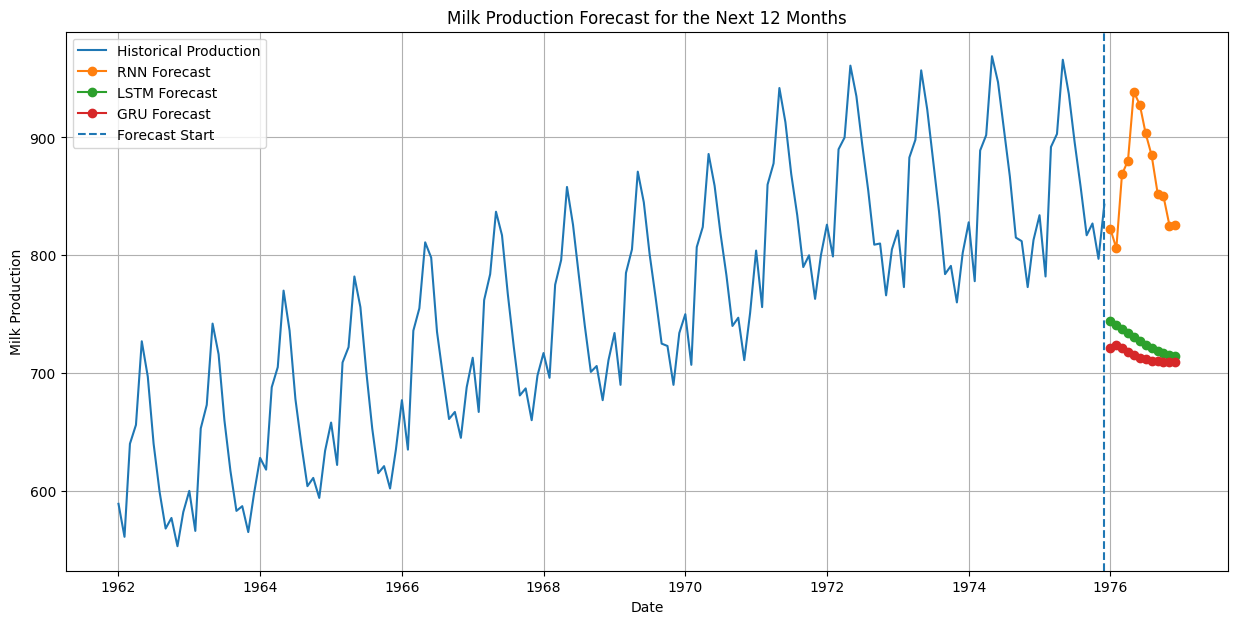

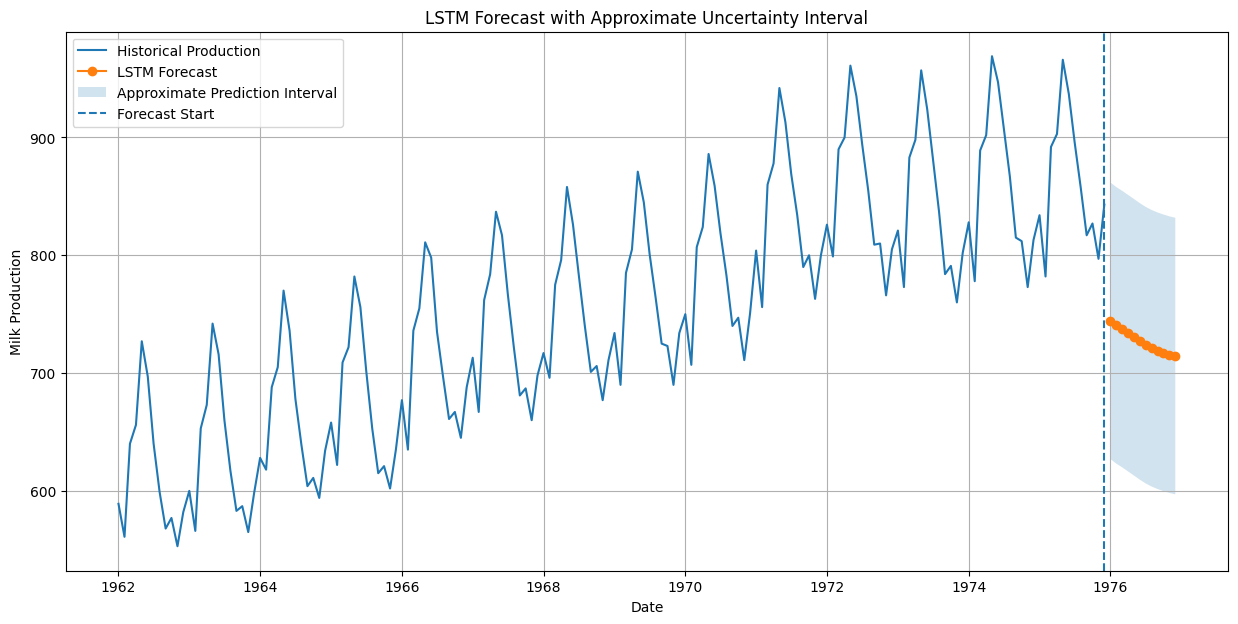

In [70]:
# ---------------------------------------------------------
# PREDICTION AND VISUALIZATION
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ---------------------------------------------------------
# Transform the complete historical dataset using the scaler
# that was fitted on the training data.
#
# This prevents us from fitting a new scaler using future
# information.
# ---------------------------------------------------------

all_scaled = scaler.transform(
    df[['Production']]
)


# ---------------------------------------------------------
# Select the final 12 months as the starting window.
# ---------------------------------------------------------

last_window = all_scaled[-window_size:]


# ---------------------------------------------------------
# Function for recursive future forecasting.
#
# The function receives a trained model and predicts one
# month at a time.
# ---------------------------------------------------------

def forecast_next_12_months(model, last_window, scaler):
    
    # Create a copy of the final historical window.
    current_window = last_window.copy()
    
    # Store scaled predictions.
    future_scaled = []
    
    # Generate 12 future predictions.
    for i in range(12):
        
        # Reshape the data for the neural network.
        model_input = current_window.reshape(
            1,
            window_size,
            1
        )
        
        # Predict the next month.
        next_prediction = model.predict(
            model_input,
            verbose=0
        )[0, 0]
        
        # Store the prediction.
        future_scaled.append(
            next_prediction
        )
        
        # Remove the oldest observation and add the new
        # prediction to the end of the window.
        current_window = np.append(
            current_window[1:],
            [[next_prediction]],
            axis=0
        )
    
    # Convert the predictions into the required shape.
    future_scaled = np.array(
        future_scaled
    ).reshape(-1, 1)
    
    # Convert scaled predictions back to original units.
    future_original = scaler.inverse_transform(
        future_scaled
    ).flatten()
    
    return future_original


# ---------------------------------------------------------
# Generate future forecasts for all three models.
# ---------------------------------------------------------

rnn_future = forecast_next_12_months(
    rnn_model,
    last_window,
    scaler
)

lstm_future = forecast_next_12_months(
    lstm_model,
    last_window,
    scaler
)

gru_future = forecast_next_12_months(
    gru_model,
    last_window,
    scaler
)


# ---------------------------------------------------------
# Create the next 12 monthly dates.
# ---------------------------------------------------------

future_dates = pd.date_range(
    start=df['Date'].max() + pd.offsets.MonthBegin(1),
    periods=12,
    freq='MS'
)


# ---------------------------------------------------------
# Create a DataFrame containing all forecasts.
# ---------------------------------------------------------

forecast_df = pd.DataFrame({
    'Date': future_dates,
    'RNN': rnn_future,
    'LSTM': lstm_future,
    'GRU': gru_future
})


# ---------------------------------------------------------
# Display the future predictions.
# ---------------------------------------------------------

print("Forecast for the next 12 months")
print(forecast_df)


# ---------------------------------------------------------
# Generate LSTM predictions on the test dataset.
#
# These predictions are used to estimate historical
# forecasting error for the approximate uncertainty interval.
# ---------------------------------------------------------

lstm_test_scaled = lstm_model.predict(
    X_test,
    verbose=0
)


# ---------------------------------------------------------
# Convert test predictions back to the original scale.
# ---------------------------------------------------------

lstm_test_predictions = scaler.inverse_transform(
    lstm_test_scaled
).flatten()


# ---------------------------------------------------------
# Convert actual test values back to the original scale.
# ---------------------------------------------------------

lstm_test_actual = scaler.inverse_transform(
    y_test
).flatten()


# ---------------------------------------------------------
# Calculate historical prediction errors.
# ---------------------------------------------------------

lstm_errors = (
    lstm_test_actual -
    lstm_test_predictions
)


# ---------------------------------------------------------
# Calculate the standard deviation of the historical errors.
# ---------------------------------------------------------

error_std = np.std(lstm_errors)


# ---------------------------------------------------------
# Create approximate prediction bounds.
#
# These are approximate uncertainty intervals based on
# historical test errors.
# ---------------------------------------------------------

forecast_df['Lower_Bound'] = (
    forecast_df['LSTM'] -
    1.96 * error_std
)

forecast_df['Upper_Bound'] = (
    forecast_df['LSTM'] +
    1.96 * error_std
)


# ---------------------------------------------------------
# Prevent the lower production bound from becoming negative.
# ---------------------------------------------------------

forecast_df['Lower_Bound'] = forecast_df[
    'Lower_Bound'
].clip(lower=0)


# ---------------------------------------------------------
# Display the final forecast table.
# ---------------------------------------------------------

print("\nLSTM Forecast with Approximate Uncertainty")
print(
    forecast_df[
        [
            'Date',
            'LSTM',
            'Lower_Bound',
            'Upper_Bound'
        ]
    ]
)


# ---------------------------------------------------------
# Plot historical production and all three forecasts.
# ---------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    df['Date'],
    df['Production'],
    label='Historical Production'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['RNN'],
    marker='o',
    label='RNN Forecast'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['LSTM'],
    marker='o',
    label='LSTM Forecast'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['GRU'],
    marker='o',
    label='GRU Forecast'
)

plt.axvline(
    x=df['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title(
    'Milk Production Forecast for the Next 12 Months'
)

plt.xlabel('Date')

plt.ylabel('Milk Production')

plt.legend()

plt.grid(True)

plt.show()


# ---------------------------------------------------------
# Plot the LSTM forecast with the approximate uncertainty
# interval.
# ---------------------------------------------------------

plt.figure(figsize=(15, 7))

plt.plot(
    df['Date'],
    df['Production'],
    label='Historical Production'
)

plt.plot(
    forecast_df['Date'],
    forecast_df['LSTM'],
    marker='o',
    label='LSTM Forecast'
)

plt.fill_between(
    forecast_df['Date'],
    forecast_df['Lower_Bound'],
    forecast_df['Upper_Bound'],
    alpha=0.2,
    label='Approximate Prediction Interval'
)

plt.axvline(
    x=df['Date'].max(),
    linestyle='--',
    label='Forecast Start'
)

plt.title(
    'LSTM Forecast with Approximate Uncertainty Interval'
)

plt.xlabel('Date')

plt.ylabel('Milk Production')

plt.legend()

plt.grid(True)

plt.show()

# Business Insights

The time series analysis of monthly milk production revealed a clear long term trend and recurring seasonal patterns. The RNN, LSTM, and GRU models were used to forecast milk production for the next 12 months. These forecasts provide useful information for planning production capacity, storage, workforce, transportation, and distribution activities.

The dairy business can use the forecasts to estimate the expected availability of milk in upcoming months and adjust production and processing activities accordingly. During periods of higher predicted production, the business can prepare sufficient processing capacity, cold storage, packaging materials, and transportation resources. During periods of lower predicted production, resources can be adjusted to avoid unnecessary operating costs and unused capacity.

The forecasts can also help with inventory and cold storage management. Since milk is a perishable product, anticipating production levels can help the business coordinate processing, storage, and distribution more efficiently and reduce potential wastage.

Forecast information can support workforce allocation by identifying months when production is expected to be higher or lower. Additional workers and operational resources can be planned during high production periods, while staffing and resources can be adjusted during lower production periods.

The forecasts can also improve transportation and distribution planning. Expected production levels can help management schedule delivery vehicles, routes, warehouse capacity, and distribution activities in advance. This can improve operational efficiency and reduce delays.

The observed seasonal patterns are particularly important because milk production is not constant throughout the year. Understanding these recurring patterns allows the business to prepare for expected seasonal changes and manage fluctuations in supply more effectively.

Overall, the forecasting models provide a data driven approach for future planning and resource allocation. By combining the 12 month forecasts with the model evaluation results, the dairy business can make better informed decisions regarding production, storage, workforce, transportation, and distribution while reducing wastage and improving operational efficiency.